<a href="https://colab.research.google.com/github/arturodeleon19/Brain_Tumor_Image_APP/blob/main/Brain_Tumor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import zipfile
import os

zip_path = '/content/Brain Tumor Image DataSet.zip'


extract_path = '/content/brain_tumor_data/'

# Create the destination directory
os.makedirs(extract_path, exist_ok=True)

# 3. Unzip the file
try:
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        print(f"Extracting files to {extract_path}...")
        zip_ref.extractall(extract_path)
        print("Extraction complete!")
except FileNotFoundError:
    print(f"Error: Could not find {zip_path}. Please check the file name and path.")

# 4. Verify the extraction by listing the contents of the new folder
print("\nContents of the extracted folder:")
for item in os.listdir(extract_path):
    print(f"- {item}")

Extracting files to /content/brain_tumor_data/...
Extraction complete!

Contents of the extracted folder:
- README.txt
- train
- test
- valid


In [2]:
import json
import os

train_dir = '/content/brain_tumor_data/train'
json_files = [f for f in os.listdir(train_dir) if f.endswith('.json')]

if json_files:
    json_path = os.path.join(train_dir, json_files[0])
    with open(json_path, 'r') as f:
        coco_data = json.load(f)

    print("Exact Category Mapping from your JSON:")
    for cat in coco_data['categories']:
        print(f"Category ID: {cat['id']} -> Category Name: {cat['name']}")
else:
    print("No JSON found.")

Exact Category Mapping from your JSON:
Category ID: 0 -> Category Name: Tumor
Category ID: 1 -> Category Name: 0
Category ID: 2 -> Category Name: 1


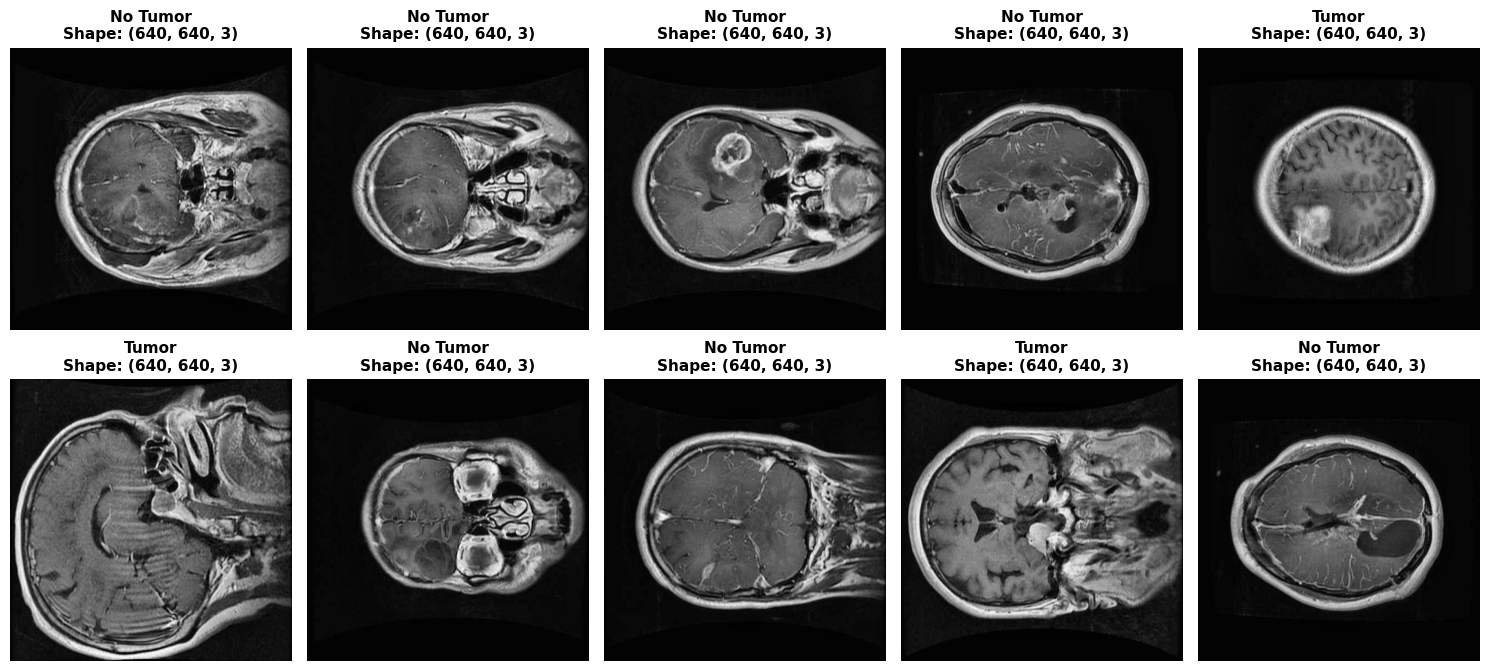

In [3]:
import os
import json
import random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

train_dir = '/content/brain_tumor_data/train'

# 1. Find the COCO JSON file in the train directory
json_files = [f for f in os.listdir(train_dir) if f.endswith('.json')]

if not json_files:
    print("No JSON annotation file found in the train directory.")
else:
    json_path = os.path.join(train_dir, json_files[0])

    # 2. Load the JSON data
    with open(json_path, 'r') as f:
        coco_data = json.load(f)

    # 3. Map category IDs based on your exact JSON output
    categories = {}
    for cat in coco_data['categories']:
        name_str = str(cat['name']).strip()
        if name_str == '0':
            categories[cat['id']] = 'No Tumor'
        elif name_str == '1' or name_str.lower() == 'tumor':
            categories[cat['id']] = 'Tumor'
        else:
            categories[cat['id']] = name_str

    # Map image IDs to their file names
    images_info = {img['id']: img['file_name'] for img in coco_data['images']}

    # 4. Map image IDs to their labels based on the annotations
    image_labels = {img_id: set() for img_id in images_info.keys()}

    for ann in coco_data['annotations']:
        img_id = ann['image_id']
        cat_id = ann['category_id']

        # Look up the mapped name
        category_name = categories.get(cat_id, "Unknown")

        if img_id in image_labels:
            image_labels[img_id].add(category_name)

    # 5. Randomly select 10 images
    all_image_ids = list(images_info.keys())
    sample_size = min(10, len(all_image_ids))
    selected_ids = random.sample(all_image_ids, sample_size)

    # 6. Plot the 10 images and their corresponding labels
    plt.figure(figsize=(15, 7)) # Increased height slightly to accommodate the second line of text

    for i, img_id in enumerate(selected_ids):
        file_name = images_info[img_id]
        img_path = os.path.join(train_dir, file_name)

        labels_set = image_labels[img_id]

        # Determine final text.
        if "Tumor" in labels_set:
            label_text = "Tumor"
        elif len(labels_set) == 0 or list(labels_set) == ['No Tumor']:
            label_text = "No Tumor"
        else:
            label_text = ", ".join(labels_set)

        # Load and plot the image
        try:
            img = Image.open(img_path)

            # Convert to numpy array to get the exact matrix shape (Height, Width, Channels)
            img_shape = np.array(img).shape

            plt.subplot(2, 5, i + 1)
            plt.imshow(img, cmap='gray') # Grayscale for MRI

            # Add \n to stack the text on two lines
            plt.title(f"{label_text}\nShape: {img_shape}", fontsize=11, fontweight='bold')
            plt.axis('off')
        except FileNotFoundError:
            print(f"Image {file_name} not found at {img_path}.")

    plt.tight_layout()
    plt.show()

In [4]:
import os
import json
import tensorflow as tf

# Baseline parameters
IMG_HEIGHT = 224
IMG_WIDTH = 224
BATCH_SIZE = 32

def create_path_and_label_lists(directory):
    """Parses the COCO JSON in the directory and returns lists of file paths and binary labels."""
    json_files = [f for f in os.listdir(directory) if f.endswith('.json')]
    if not json_files:
        raise FileNotFoundError(f"No JSON annotation file found in {directory}")

    json_path = os.path.join(directory, json_files[0])

    with open(json_path, 'r') as f:
        coco_data = json.load(f)

    # Map category IDs to binary labels: 0 for No Tumor, 1 for Tumor
    categories = {}
    for cat in coco_data['categories']:
        name_str = str(cat['name']).strip().lower()
        if name_str == '1' or name_str == 'tumor':
            categories[cat['id']] = 1
        elif name_str == '0' or name_str == 'no tumor':
            categories[cat['id']] = 0
        else:
            categories[cat['id']] = 0 # Default to 0 if unknown

    images_info = {img['id']: img['file_name'] for img in coco_data['images']}

    # Initialize all images with label 0 (No Tumor)
    image_labels = {img_id: 0 for img_id in images_info.keys()}

    # Update to 1 (Tumor) if an annotation exists for it
    for ann in coco_data['annotations']:
        img_id = ann['image_id']
        cat_id = ann['category_id']
        if categories.get(cat_id) == 1:
            image_labels[img_id] = 1

    # Convert dictionaries to ordered lists
    file_paths = []
    labels = []

    for img_id, file_name in images_info.items():
        file_paths.append(os.path.join(directory, file_name))
        labels.append(image_labels[img_id])

    return file_paths, labels

def process_path(file_path, label):
    """Reads, decodes, resizes, and normalizes the image."""
    # Read the raw byte string from the file
    img = tf.io.read_file(file_path)

    # Decode the image (detects format automatically, forces 3 channels)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)

    # Explicitly set shape before resizing to prevent TensorFlow graph errors
    img.set_shape([None, None, 3])

    # Resize the image to 224x224
    img = tf.image.resize(img, [IMG_HEIGHT, IMG_WIDTH])

    # Normalize pixel values from [0, 255] to [0, 1]
    img = img / 255.0

    return img, label

# 1. Parse the directories
train_paths, train_labels = create_path_and_label_lists('/content/brain_tumor_data/train')
valid_paths, valid_labels = create_path_and_label_lists('/content/brain_tumor_data/valid')

print(f"Found {len(train_paths)} training images.")
print(f"Found {len(valid_paths)} validation images.")

# 2. Create base tf.data.Datasets
train_ds = tf.data.Dataset.from_tensor_slices((train_paths, train_labels))
valid_ds = tf.data.Dataset.from_tensor_slices((valid_paths, valid_labels))

# 3. Optimize the datasets (Map preprocessing, shuffle, batch, prefetch)
AUTOTUNE = tf.data.AUTOTUNE

# Train Dataset: Map -> Shuffle -> Batch -> Prefetch
train_ds = train_ds.map(process_path, num_parallel_calls=AUTOTUNE)
train_ds = train_ds.shuffle(buffer_size=len(train_paths))
train_ds = train_ds.batch(BATCH_SIZE)
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)

# Valid Dataset: Map -> Batch -> Prefetch (No need to shuffle validation data)
valid_ds = valid_ds.map(process_path, num_parallel_calls=AUTOTUNE)
valid_ds = valid_ds.batch(BATCH_SIZE)
valid_ds = valid_ds.prefetch(buffer_size=AUTOTUNE)

# 4. Quick check of the dataset shapes
for image_batch, label_batch in train_ds.take(1):
    print(f"\nBatch Image shape: {image_batch.shape}")
    print(f"Batch Label shape: {label_batch.shape}")
    print(f"First 5 labels in batch: {label_batch.numpy()[:5]}")

Found 1502 training images.
Found 429 validation images.

Batch Image shape: (32, 224, 224, 3)
Batch Label shape: (32,)
First 5 labels in batch: [1 0 1 1 1]


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,089 (42.61 MB)

 Trainable params: 11,169,089 (42.61 MB)

 Non-trainable params: 0 (0.00 B)


Starting training...

Starting Phase 2: Fine-Tuning with Early Stopping...
Epoch 1/100
47/47 ━━━━━━━━━━━━━━━━━━━━ 25s 296ms/step - accuracy: 0.7956 - loss: 0.5419 - val_accuracy: 0.8695 - val_loss: 0.3324
Epoch 2/100
47/47 ━━━━━━━━━━━━━━━━━━━━ 3s 57ms/step - accuracy: 0.9308 - loss: 0.1767 - val_accuracy: 0.9767 - val_loss: 0.0698
Epoch 3/100
47/47 ━━━━━━━━━━━━━━━━━━━━ 3s 57ms/step - accuracy: 0.9800 - loss: 0.0689 - val_accuracy: 0.9907 - val_loss: 0.0287
Epoch 4/100
47/47 ━━━━━━━━━━━━━━━━━━━━ 3s 56ms/step - accuracy: 0.9814 - loss: 0.0543 - val_accuracy: 0.9837 - val_loss: 0.0366
Epoch 5/100
47/47 ━━━━━━━━━━━━━━━━━━━━ 3s 57ms/step - accuracy: 0.9840 - loss: 0.0524 - val_accuracy: 0.9930 - val_loss: 0.0250
Epoch 6/100
47/47 ━━━━━━━━━━━━━━━━━━━━ 3s 57ms/step - accuracy: 0.9887 - loss: 0.0381 - val_accuracy: 0.9977 - val_loss: 0.0200
Epoch 7/100
47/47 ━━━━━━━━━━━━━━━━━━━━ 3s 58ms/step - accuracy: 0.9920 - loss: 0.0278 - val_accuracy: 0.9977 - val_loss: 0.0149
Epoch 8/100
47/47 ━━━━━━━━

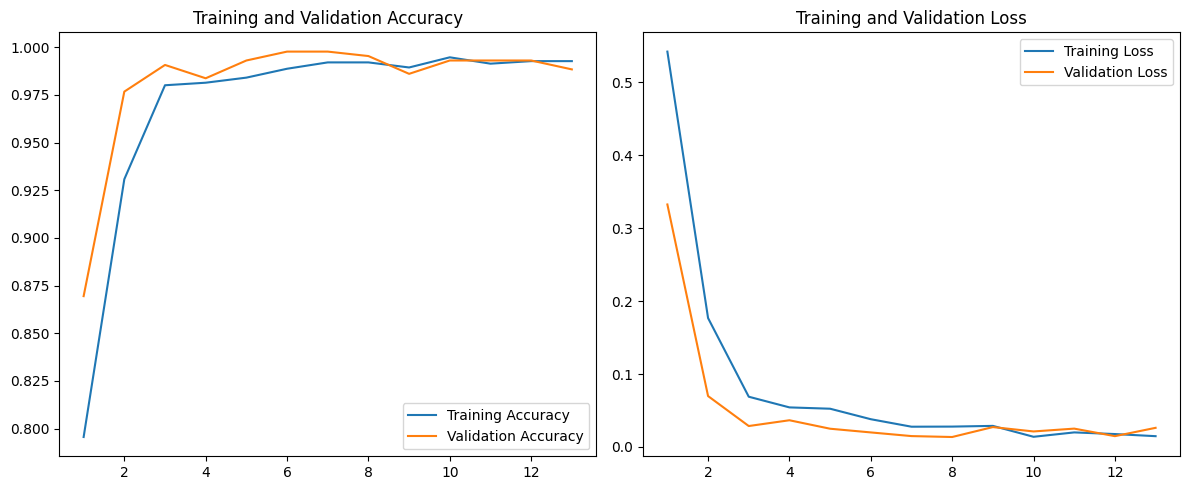

In [5]:
import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

# 1. Define the baseline CNN architecture
def build_baseline_model(input_shape=(224, 224, 3)):
    model = models.Sequential([
        # First Convolutional Block
        layers.Conv2D(32, (3, 3), activation='relu', input_shape=input_shape),
        layers.MaxPooling2D(pool_size=(2, 2)),

        # Second Convolutional Block
        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.MaxPooling2D(pool_size=(2, 2)),

        # Third Convolutional Block
        layers.Conv2D(128, (3, 3), activation='relu'),
        layers.MaxPooling2D(pool_size=(2, 2)),

        # Flatten the feature maps into a 1D array
        layers.Flatten(),

        # Fully Connected Block
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.5), # Helps prevent overfitting by randomly dropping 50% of connections

        # Output Layer: 1 neuron with sigmoid activation for binary classification (0 or 1)
        layers.Dense(1, activation='sigmoid')
    ])
    return model

# 2. Instantiate and compile the model
model = build_baseline_model()

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Display the model architecture
model.summary()

# 3. Train the model
# Using a small number of epochs for the baseline test
EPOCHS = 100

print("\nStarting training...")

# EarlyStopping callback
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

print("\nStarting Phase 2: Fine-Tuning with Early Stopping...")
history = model.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=EPOCHS,
    callbacks=[early_stopping]
)


# Plot the training history to evaluate performance and check for overfitting
def plot_history(history):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs_range = range(1, len(acc) + 1)

    plt.figure(figsize=(12, 5))

    # Plot Accuracy
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, label='Training Accuracy')
    plt.plot(epochs_range, val_acc, label='Validation Accuracy')
    plt.legend(loc='lower right')
    plt.title('Training and Validation Accuracy')

    # Plot Loss
    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, label='Training Loss')
    plt.plot(epochs_range, val_loss, label='Validation Loss')
    plt.legend(loc='upper right')
    plt.title('Training and Validation Loss')

    plt.tight_layout()
    plt.show()

plot_history(history)

In [6]:
from google.colab import files

keras_model_name = 'brain_tumor_base.keras'
model.save(keras_model_name)
print(f"Saved standard model: {keras_model_name}")

# Trigger download to your local computer
files.download(keras_model_name)

Saved standard model: brain_tumor_base.keras


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [7]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0

def build_transfer_learning_model(input_shape=(224, 224, 3)):
    # Load the pre-trained base model
    # include_top=False removes the original 1000-class output layer
    # weights='imagenet' loads the pre-trained feature extraction weights
    base_model = EfficientNetB0(
        weights='imagenet',
        include_top=False,
        input_shape=input_shape
    )

    #  Freeze the base model (so we don't destroy the pre-trained weights during initial training)
    base_model.trainable = False

    #  Build the new model on top
    model = models.Sequential([
        base_model,

        # GlobalAveragePooling2D is preferred over Flatten for modern architectures
        # It drastically reduces the number of parameters, preventing overfitting
        layers.GlobalAveragePooling2D(),

        # Add dense layer for our specific problem
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.5),

        # Final binary output
        layers.Dense(1, activation='sigmoid')
    ])

    return model, base_model

# Instantiate the model
model, base_model = build_transfer_learning_model()

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,213,668 (16.07 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [8]:
import os
import json
import tensorflow as tf

# Baseline parameters
IMG_HEIGHT = 224
IMG_WIDTH = 224
BATCH_SIZE = 32

def create_path_and_label_lists(directory):
    """Parses the COCO JSON in the directory and returns lists of file paths and binary labels."""
    json_files = [f for f in os.listdir(directory) if f.endswith('.json')]
    if not json_files:
        raise FileNotFoundError(f"No JSON annotation file found in {directory}")

    json_path = os.path.join(directory, json_files[0])

    with open(json_path, 'r') as f:
        coco_data = json.load(f)

    # Map category IDs to binary labels: 0 for No Tumor, 1 for Tumor
    categories = {}
    for cat in coco_data['categories']:
        name_str = str(cat['name']).strip().lower()
        if name_str == '1' or name_str == 'tumor':
            categories[cat['id']] = 1
        elif name_str == '0' or name_str == 'no tumor':
            categories[cat['id']] = 0
        else:
            categories[cat['id']] = 0 # Default to 0 if unknown

    images_info = {img['id']: img['file_name'] for img in coco_data['images']}

    # Initialize all images with label 0 (No Tumor)
    image_labels = {img_id: 0 for img_id in images_info.keys()}

    # Update to 1 (Tumor) if an annotation exists for it
    for ann in coco_data['annotations']:
        img_id = ann['image_id']
        cat_id = ann['category_id']
        if categories.get(cat_id) == 1:
            image_labels[img_id] = 1

    # Convert dictionaries to ordered lists
    file_paths = []
    labels = []

    for img_id, file_name in images_info.items():
        file_paths.append(os.path.join(directory, file_name))
        labels.append(image_labels[img_id])

    return file_paths, labels

def process_path(file_path, label):
    """Reads, decodes, resizes, and normalizes the image."""
    # Read the raw byte string from the file
    img = tf.io.read_file(file_path)

    # Decode the image (detects format automatically, forces 3 channels)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)

    # Explicitly set shape before resizing to prevent TensorFlow graph errors
    img.set_shape([None, None, 3])

    # Resize the image to 224x224
    img = tf.image.resize(img, [IMG_HEIGHT, IMG_WIDTH])


    return img, label

# 1. Parse the directories
train_paths, train_labels = create_path_and_label_lists('/content/brain_tumor_data/train')
valid_paths, valid_labels = create_path_and_label_lists('/content/brain_tumor_data/valid')

print(f"Found {len(train_paths)} training images.")
print(f"Found {len(valid_paths)} validation images.")

# 2. Create base tf.data.Datasets
train_ds = tf.data.Dataset.from_tensor_slices((train_paths, train_labels))
valid_ds = tf.data.Dataset.from_tensor_slices((valid_paths, valid_labels))

# 3. Optimize the datasets (Map preprocessing, shuffle, batch, prefetch)
AUTOTUNE = tf.data.AUTOTUNE

# Train Dataset: Map -> Shuffle -> Batch -> Prefetch
train_ds = train_ds.map(process_path, num_parallel_calls=AUTOTUNE)
train_ds = train_ds.shuffle(buffer_size=len(train_paths))
train_ds = train_ds.batch(BATCH_SIZE)
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)

# Valid Dataset: Map -> Batch -> Prefetch (No need to shuffle validation data)
valid_ds = valid_ds.map(process_path, num_parallel_calls=AUTOTUNE)
valid_ds = valid_ds.batch(BATCH_SIZE)
valid_ds = valid_ds.prefetch(buffer_size=AUTOTUNE)

# 4. Quick check of the dataset shapes
for image_batch, label_batch in train_ds.take(1):
    print(f"\nBatch Image shape: {image_batch.shape}")
    print(f"Batch Label shape: {label_batch.shape}")
    print(f"First 5 labels in batch: {label_batch.numpy()[:5]}")

Found 1502 training images.
Found 429 validation images.

Batch Image shape: (32, 224, 224, 3)
Batch Label shape: (32,)
First 5 labels in batch: [1 0 0 1 1]



Starting transfer learning training (Feature Extraction)...

Starting Phase 2: Fine-Tuning with Early Stopping...
Epoch 1/100
47/47 ━━━━━━━━━━━━━━━━━━━━ 81s 943ms/step - accuracy: 0.8562 - loss: 0.3336 - val_accuracy: 0.9464 - val_loss: 0.1682
Epoch 2/100
47/47 ━━━━━━━━━━━━━━━━━━━━ 3s 45ms/step - accuracy: 0.9308 - loss: 0.1636 - val_accuracy: 0.9510 - val_loss: 0.1547
Epoch 3/100
47/47 ━━━━━━━━━━━━━━━━━━━━ 3s 44ms/step - accuracy: 0.9547 - loss: 0.1273 - val_accuracy: 0.9627 - val_loss: 0.1134
Epoch 4/100
47/47 ━━━━━━━━━━━━━━━━━━━━ 3s 42ms/step - accuracy: 0.9534 - loss: 0.1165 - val_accuracy: 0.9580 - val_loss: 0.1304
Epoch 5/100
47/47 ━━━━━━━━━━━━━━━━━━━━ 3s 44ms/step - accuracy: 0.9667 - loss: 0.0951 - val_accuracy: 0.9650 - val_loss: 0.0910
Epoch 6/100
47/47 ━━━━━━━━━━━━━━━━━━━━ 3s 44ms/step - accuracy: 0.9700 - loss: 0.0892 - val_accuracy: 0.9720 - val_loss: 0.0850
Epoch 7/100
47/47 ━━━━━━━━━━━━━━━━━━━━ 3s 42ms/step - accuracy: 0.9747 - loss: 0.0750 - val_accuracy: 0.9650 - val_

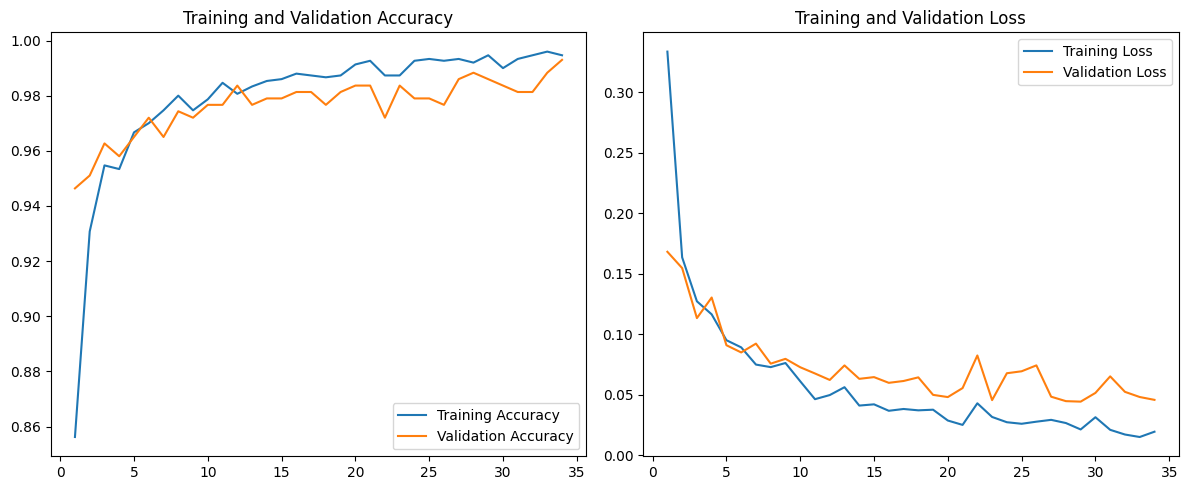

In [9]:
import matplotlib.pyplot as plt

# Train the Transfer Learning Model
# We use 10 epochs for the initial feature extraction phase
EPOCHS = 100

print("\nStarting transfer learning training (Feature Extraction)...")

# Define the EarlyStopping callback
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

# Add the callback to the fit function
print("\nStarting Phase 2: Fine-Tuning with Early Stopping...")
history_netb0 = model.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=EPOCHS,
    callbacks=[early_stopping]
)


#  Plot the training history to evaluate performance
def plot_history(history):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs_range = range(1, len(acc) + 1)

    plt.figure(figsize=(12, 5))

    # Plot Accuracy
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, label='Training Accuracy')
    plt.plot(epochs_range, val_acc, label='Validation Accuracy')
    plt.legend(loc='lower right')
    plt.title('Training and Validation Accuracy')

    # Plot Loss
    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, label='Training Loss')
    plt.plot(epochs_range, val_loss, label='Validation Loss')
    plt.legend(loc='upper right')
    plt.title('Training and Validation Loss')

    plt.tight_layout()
    plt.show()

# function history_2 variable
plot_history(history_netb0)

In [10]:
from google.colab import files

keras_model_name = 'brain_tumor_EfficientB0.keras'
model.save(keras_model_name)
print(f"Saved standard model: {keras_model_name}")

# Trigger download to your local computer
files.download(keras_model_name)

Saved standard model: brain_tumor_EfficientB0.keras


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Number of trainable variables after unfreezing: 23

Starting Phase 2: Fine-Tuning...

Starting Phase 2: Fine-Tuning with Early Stopping...
Epoch 1/100
47/47 ━━━━━━━━━━━━━━━━━━━━ 56s 598ms/step - accuracy: 0.9481 - loss: 0.1240 - val_accuracy: 0.9837 - val_loss: 0.0504
Epoch 2/100
47/47 ━━━━━━━━━━━━━━━━━━━━ 3s 48ms/step - accuracy: 0.9734 - loss: 0.0735 - val_accuracy: 0.9814 - val_loss: 0.0522
Epoch 3/100
47/47 ━━━━━━━━━━━━━━━━━━━━ 3s 47ms/step - accuracy: 0.9740 - loss: 0.0658 - val_accuracy: 0.9790 - val_loss: 0.0546
Epoch 4/100
47/47 ━━━━━━━━━━━━━━━━━━━━ 3s 47ms/step - accuracy: 0.9807 - loss: 0.0610 - val_accuracy: 0.9767 - val_loss: 0.0535
Epoch 5/100
47/47 ━━━━━━━━━━━━━━━━━━━━ 3s 47ms/step - accuracy: 0.9867 - loss: 0.0475 - val_accuracy: 0.9767 - val_loss: 0.0559
Epoch 6/100
47/47 ━━━━━━━━━━━━━━━━━━━━ 3s 47ms/step - accuracy: 0.9827 - loss: 0.0521 - val_accuracy: 0.9767 - val_loss: 0.0592
Epoch 6: early stopping
Restoring model weights from the end of the best epoch: 1.


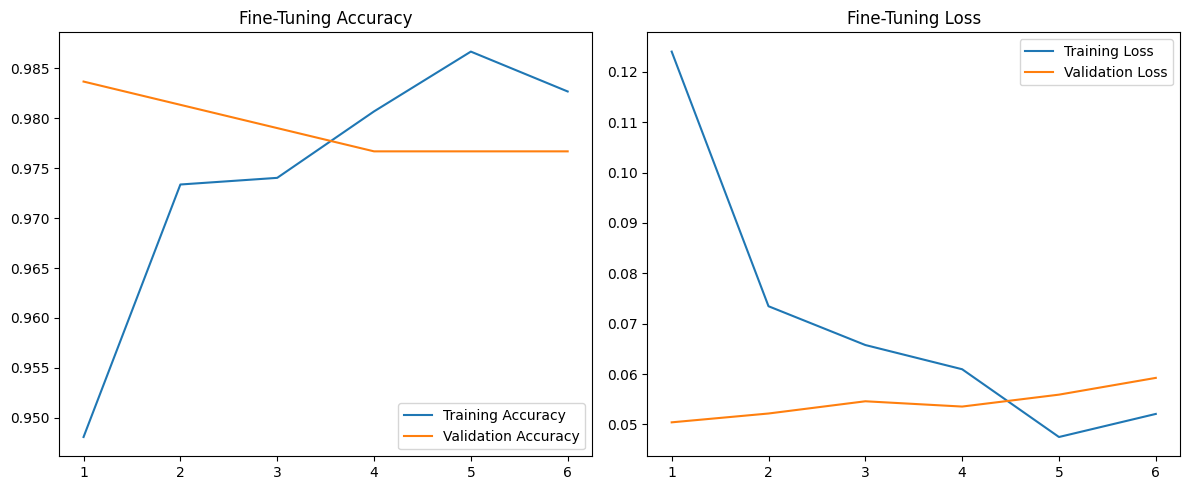

In [11]:
import tensorflow as tf
import matplotlib.pyplot as plt

# 1. Unfreeze the base model completely
base_model.trainable = True

# 2. Freeze all layers EXCEPT the top 20 layers
# EfficientNetB0 has 237 layers. We only want to fine-tune the very last blocks.
for layer in base_model.layers[:-20]:
    layer.trainable = False

# 3. Recompile the model with a severely reduced learning rate
# We use 1e-5 (0.00001) instead of the default 1e-3
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print("Number of trainable variables after unfreezing:", len(model.trainable_variables))

# 4. Train the fine-tuned model
FINE_TUNE_EPOCHS = 100

print("\nStarting Phase 2: Fine-Tuning...")

# Define the EarlyStopping callback
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

# Add the callback to the fit function
print("\nStarting Phase 2: Fine-Tuning with Early Stopping...")
history_netb0_finetune = model.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=FINE_TUNE_EPOCHS,
    callbacks=[early_stopping]
)

# 5. Plot the fine-tuning history
def plot_history(history):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs_range = range(1, len(acc) + 1)

    plt.figure(figsize=(12, 5))

    # Plot Accuracy
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, label='Training Accuracy')
    plt.plot(epochs_range, val_acc, label='Validation Accuracy')
    plt.legend(loc='lower right')
    plt.title('Fine-Tuning Accuracy')

    # Plot Loss
    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, label='Training Loss')
    plt.plot(epochs_range, val_loss, label='Validation Loss')
    plt.legend(loc='upper right')
    plt.title('Fine-Tuning Loss')

    plt.tight_layout()
    plt.show()

plot_history(history_netb0_finetune)

In [12]:
from google.colab import files

keras_model_name = 'brain_tumor_EfficientB0_FT.keras'
model.save(keras_model_name)
print(f"Saved standard model: {keras_model_name}")

# Trigger download to your local computer
files.download(keras_model_name)

Saved standard model: brain_tumor_EfficientB0_FT.keras


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>